### Data Preparation

In [2]:
import pandas as pd

df = pd.read_csv("Olympics data.csv", encoding="latin1") 

In [2]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 15433 entries, 0 to 15432
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   City          15316 non-null  str    
 1   Year          15316 non-null  float64
 2   Sport         15316 non-null  str    
 3   Discipline    15316 non-null  str    
 4   Event         15316 non-null  str    
 5   Athlete       15316 non-null  str    
 6   Gender        15316 non-null  str    
 7   Country_Code  15316 non-null  str    
 8   Country       15316 non-null  str    
 9   Event_gender  15316 non-null  str    
 10  Medal         15316 non-null  str    
dtypes: float64(1), str(10)
memory usage: 1.3 MB
None


In [3]:
print(df.isnull().sum())
df_cleaned = df.dropna()
print(df_cleaned.info())

City            117
Year            117
Sport           117
Discipline      117
Event           117
Athlete         117
Gender          117
Country_Code    117
Country         117
Event_gender    117
Medal           117
dtype: int64
<class 'pandas.DataFrame'>
Index: 15316 entries, 0 to 15432
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   City          15316 non-null  str    
 1   Year          15316 non-null  float64
 2   Sport         15316 non-null  str    
 3   Discipline    15316 non-null  str    
 4   Event         15316 non-null  str    
 5   Athlete       15316 non-null  str    
 6   Gender        15316 non-null  str    
 7   Country_Code  15316 non-null  str    
 8   Country       15316 non-null  str    
 9   Event_gender  15316 non-null  str    
 10  Medal         15316 non-null  str    
dtypes: float64(1), str(10)
memory usage: 1.4 MB
None


### EDA 

In [4]:
df.head()

,City,Year,Sport,Discipline,Event,Athlete,Gender,Country_Code,Country,Event_gender,Medal
0,Montreal,1976.0,Aquatics,Diving,3m springboard,"KÖHLER, Christa",Women,GDR,East Germany,W,Silver
1,Montreal,1976.0,Aquatics,Diving,3m springboard,"KOSENKOV, Aleksandr",Men,URS,Soviet Union,M,Bronze
2,Montreal,1976.0,Aquatics,Diving,3m springboard,"BOGGS, Philip George",Men,USA,United States,M,Gold
3,Montreal,1976.0,Aquatics,Diving,3m springboard,"CAGNOTTO, Giorgio Franco",Men,ITA,Italy,M,Silver
4,Montreal,1976.0,Aquatics,Diving,10m platform,"WILSON, Deborah Keplar",Women,USA,United States,W,Bronze


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Summary Statistics:")
df.astype(object).describe()  # Includes numerical & categorical features

Summary Statistics:


,City,Year,Sport,Discipline,Event,Athlete,Gender,Country_Code,Country,Event_gender,Medal
count,15316,15316.0,15316,15316,15316,15316,15316,15316,15316,15316,15316
unique,9,9.0,28,41,293,11337,2,128,127,3,3
top,Beijing,2008.0,Aquatics,Athletics,hockey,"PHELPS, Michael",Men,USA,United States,M,Bronze
freq,2042,2042.0,2210,1523,817,16,9388,1992,1992,8817,5258


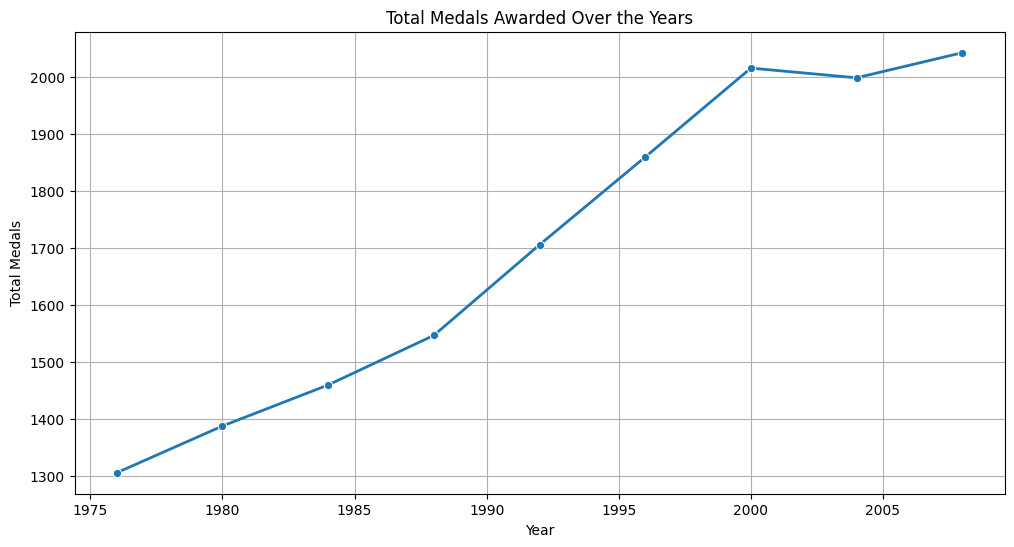

In [55]:
# 2. Medal trends over the years
medals_per_year = df.groupby("Year")["Medal"].count()

plt.figure(figsize=(12, 6))
sns.lineplot(x=medals_per_year.index, y=medals_per_year.values, marker="o", linewidth=2)
plt.xlabel("Year")
plt.ylabel("Total Medals")
plt.title("Total Medals Awarded Over the Years")
plt.grid(True)
plt.show()

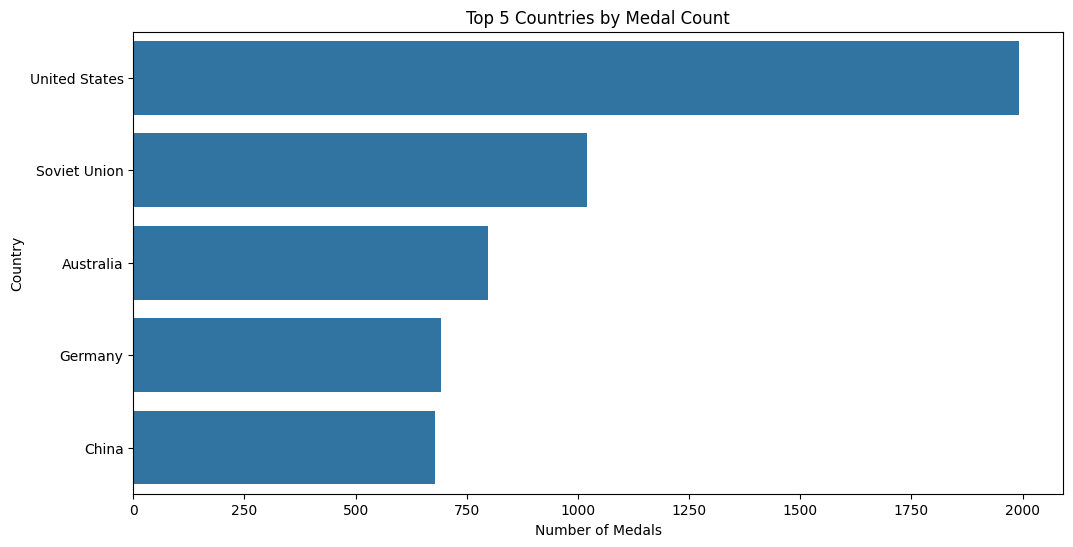

In [57]:
# 3. Top-performing countries
top_countries = df["Country"].value_counts().head(5)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.xlabel("Number of Medals")
plt.ylabel("Country")
plt.title("Top 5 Countries by Medal Count")
plt.show()

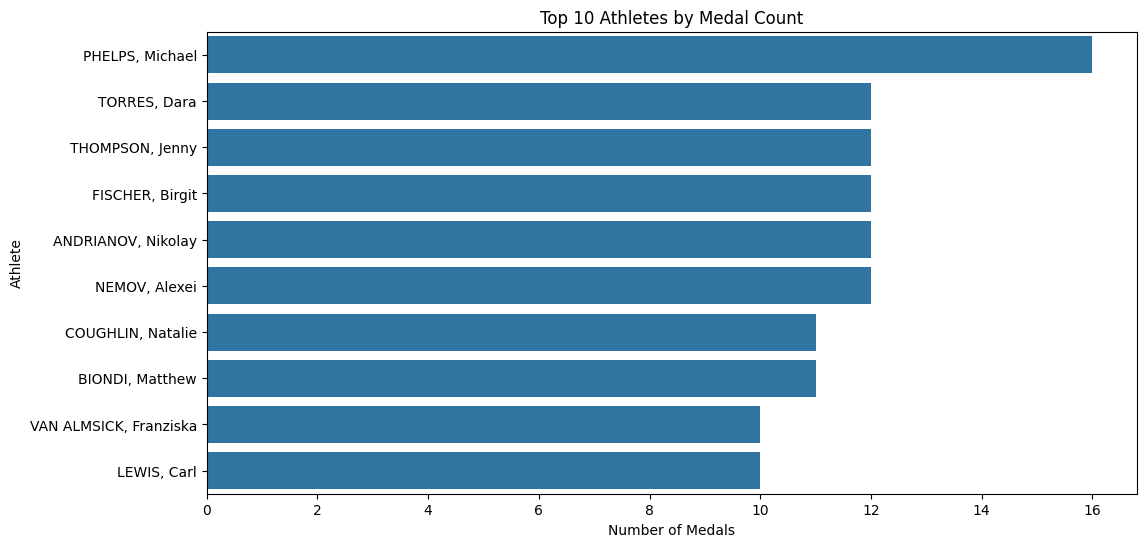

In [58]:

# 4. Top-performing athletes
top_athletes = df["Athlete"].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_athletes.values, y=top_athletes.index)
plt.xlabel("Number of Medals")
plt.ylabel("Athlete")
plt.title("Top 10 Athletes by Medal Count")
plt.show()

### Visualizing Key Insights

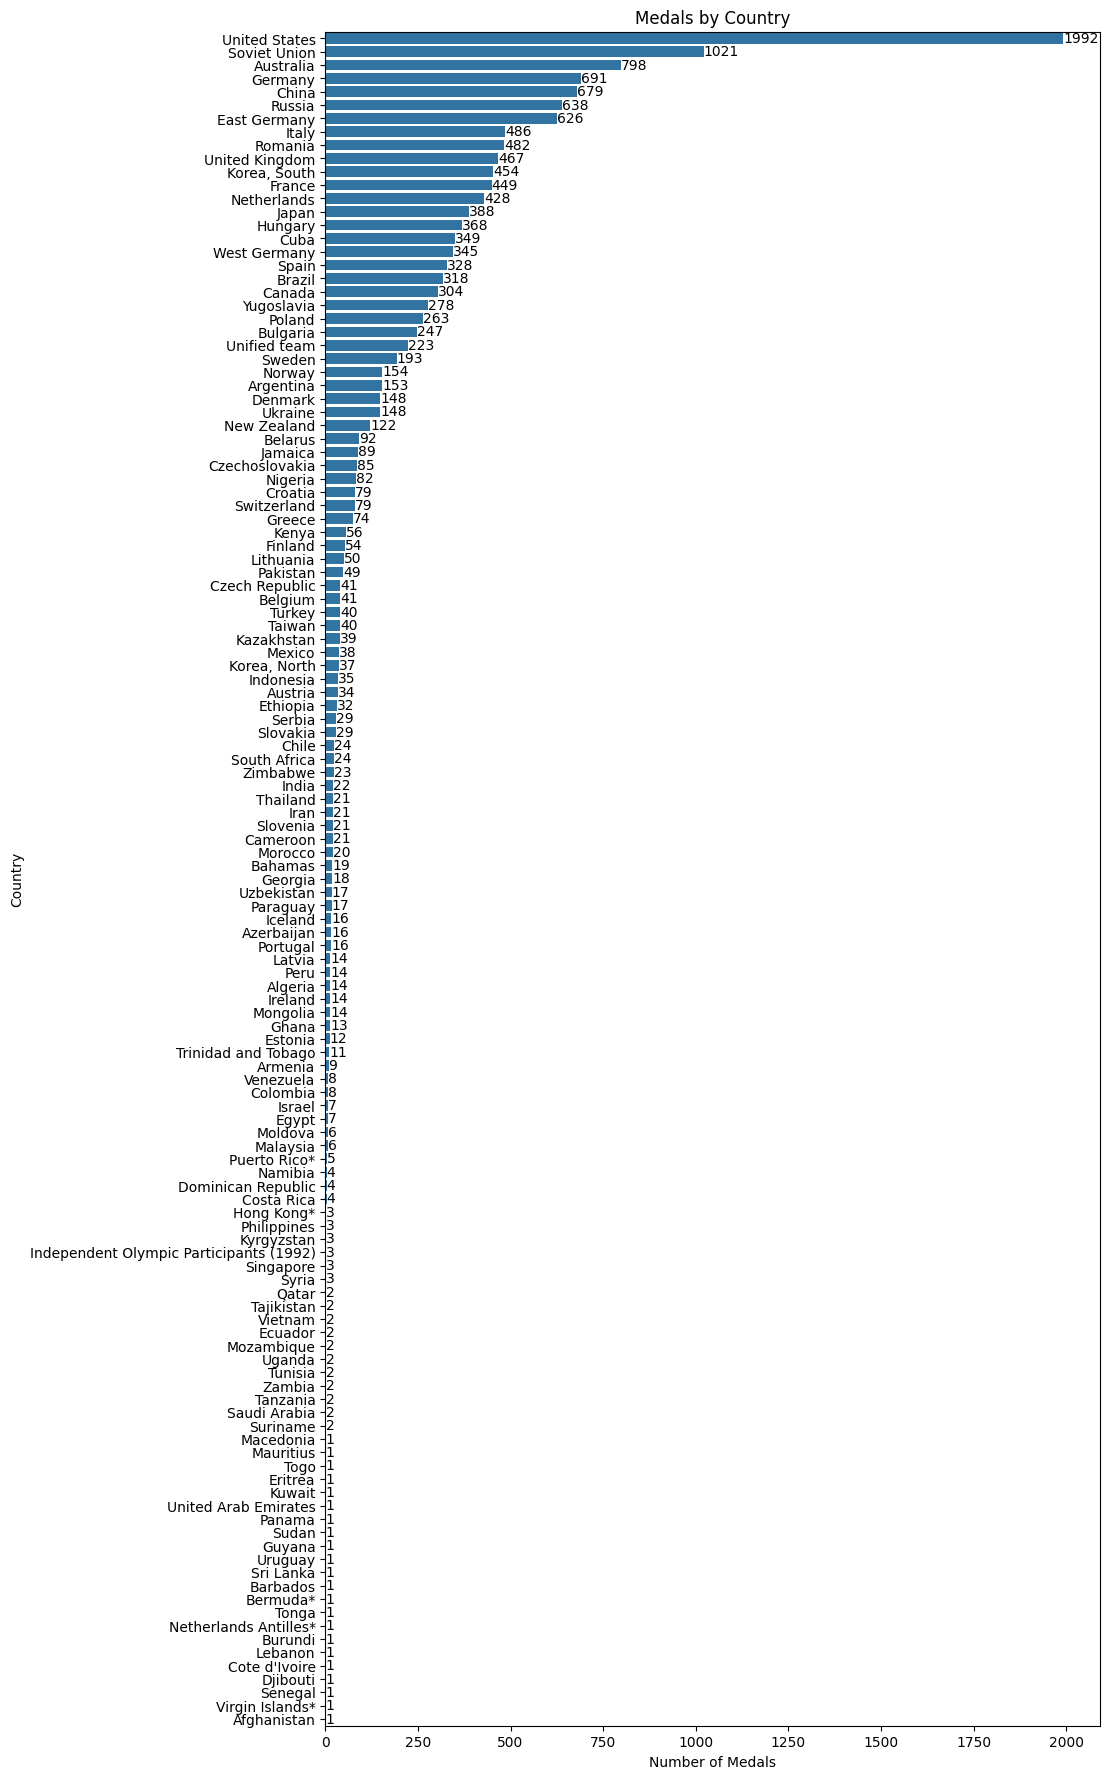

In [59]:
plt.figure(figsize=(10, 22))
ax = sns.countplot(y=df["Country"], order=df["Country"].value_counts().index)

# Add value labels on each bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_width())}',  # Convert count to integer
                (p.get_width(), p.get_y() + p.get_height() / 2),  # Positioning
                ha='left',  # Horizontal alignment
                va='center',  # Vertical alignment
                fontsize=10,  # Font size
                color='black')  # Text color

plt.xlabel("Number of Medals")
plt.ylabel("Country")
plt.title("Medals by Country")
plt.show()


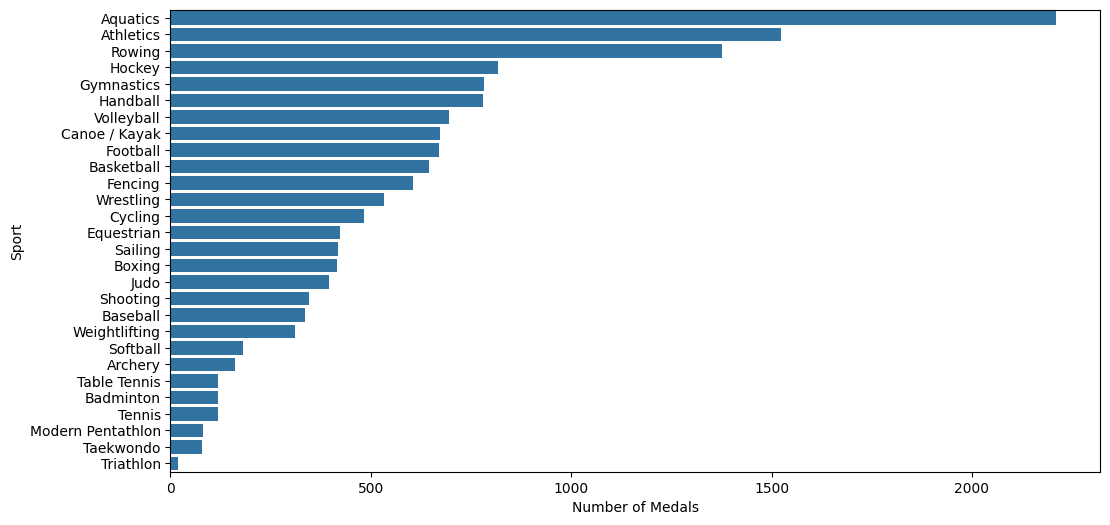

In [40]:
# 2. Medals by Sport
plt.figure(figsize=(12, 6))
sns.countplot(y=df["Sport"], order=df["Sport"].value_counts().index)
plt.xlabel("Number of Medals")
plt.ylabel("Sport")
plt.show()

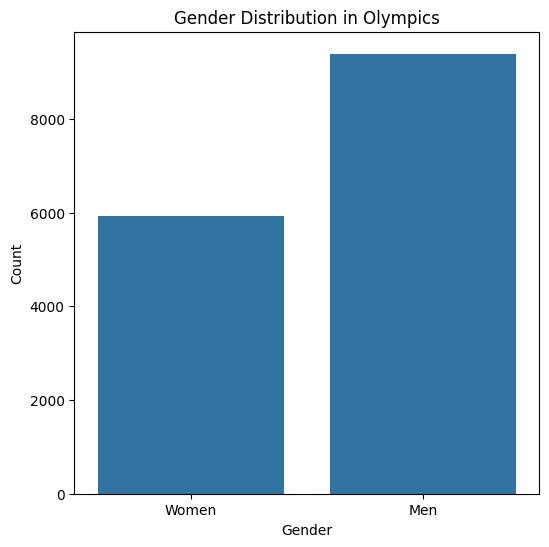

In [41]:
# 3. Gender Distribution in Events
plt.figure(figsize=(6, 6))
sns.countplot(x=df["Gender"])
plt.xlabel("Gender")
plt.ylabel("Count")
plt.title("Gender Distribution in Olympics")
plt.show()

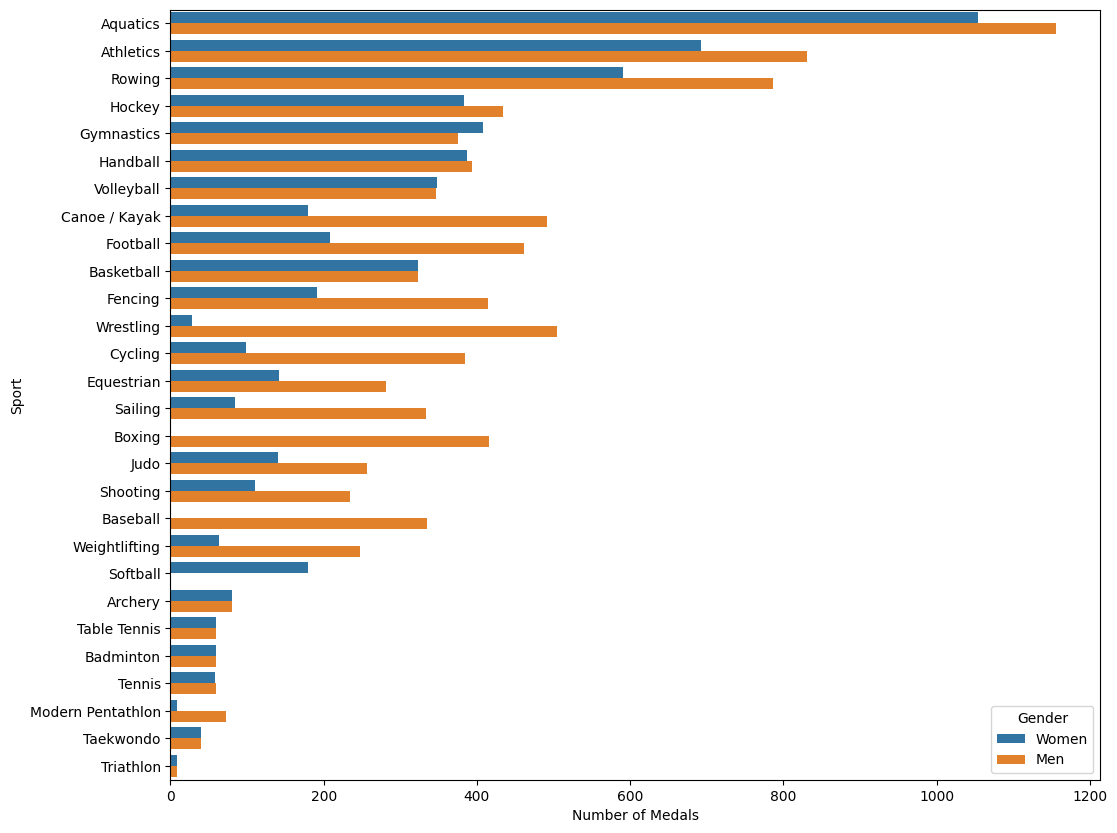

In [46]:
plt.figure(figsize=(12, 10))
sns.countplot(y=df["Sport"], hue=df["Gender"], order=df["Sport"].value_counts().index)
plt.xlabel("Number of Medals")
plt.ylabel("Sport")
plt.legend(title="Gender")
plt.show()

In [62]:
features = ['City', 'Year', 'Sport', 'Discipline', 'Event', 'Gender','Country_Code', 'Event_gender']
target = "Medal"

Index(['City', 'Year', 'Sport', 'Discipline', 'Event', 'Athlete', 'Gender',
       'Country_Code', 'Country', 'Event_gender', 'Medal'],
      dtype='object')

### Predictive analyses 

In [68]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Step 1: Select relevant features
features = ['City', 'Year', 'Sport', 'Discipline', 'Event', 'Gender','Country_Code', 'Event_gender']
target = "Medal"

# Drop rows with missing values in target column
df_clean = df.dropna(subset=[target])

# One-Hot Encoding for categorical variables
df_encoded = pd.get_dummies(df_clean[features], columns=features, drop_first=True)  # Avoid dummy variable trap

# Encode the target column (Medal: Gold, Silver, Bronze → 0,1,2)
medal_mapping = {"Bronze": 0, "Silver": 1, "Gold": 2}
df_encoded[target] = df_clean[target].map(medal_mapping)


In [69]:
# Step 2: Train-Test Split
X = df_encoded.drop(columns=[target])
y = df_encoded[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 3: Train the Model (Random Forest Classifier)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Step 4: Make Predictions
y_pred = model.predict(X_test)

# Step 5: Evaluate the Model
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.2f}")

# Detailed performance report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 0.73

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.75      0.73      1027
           1       0.71      0.73      0.72       994
           2       0.78      0.72      0.75      1043

    accuracy                           0.73      3064
   macro avg       0.74      0.74      0.74      3064
weighted avg       0.74      0.73      0.74      3064

